1a. Exploration (Eksplorasi Data & Visualisasi)

In [4]:
from google.colab import drive
import numpy as np
import pandas as pd

# 1. Hubungkan Google Drive
drive.mount('/content/drive')

# 2. Lokasi folder data di Drive
path = '/content/drive/MyDrive/data_uts_dl/'

# 3. Tampilkan isi kamus_data.md
with open(path + 'kamus_data.md', 'r') as f:
    print("=== ISI KAMUS DATA ===")
    print(f.read())

# 4. Cek struktur file klasifikasi_train.npz
data_train = np.load(path + 'klasifikasi_train.npz')
print("\n=== STRUKTUR KLASIFIKASI_TRAIN.NPZ ===")
for k in data_train.files:
    print(f"- {k}: shape={data_train[k].shape}, dtype={data_train[k].dtype}")

# 5. Cek 5 baris pertama metadata train
meta_train = pd.read_csv(path + 'klasifikasi_train_meta.csv')
print("\n=== CONTOH METADATA TRAIN ===")
print(meta_train.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== ISI KAMUS DATA ===
# Kamus data UTS Deep Learning

Semua kelompok menerima data yang sama. Label data uji tidak dibagikan.

## Tugas 1: klasifikasi_train.npz, klasifikasi_test.npz, klasifikasi_*_meta.csv

Satu sampel per unit produk dari pabrik komponen fiktif. Baris ke-i di berkas meta
memakai `indeks` = i pada array di berkas npz.

| Isi | Keterangan |
| --- | --- |
| `gambar` | Array uint8 (N, 64, 64), foto permukaan produk |
| `sensor` | Array float16 (N, 3, 128): suhu (C), getaran (relatif), arus (A) selama penekanan. NaN berarti data tidak terekam |
| id_unit | ID unit produk |
| lini | Lini produksi (A atau B) |
| shift | Shift produksi |
| id_mesin | Mesin penekan |
| batch_material | Batch bahan baku |
| kelas | Label: normal, gores, noda, retak, gelembung, las_dingin, kontaminasi. Hanya di data latih |

Label data latih berasal dari inspektur da

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Load data test juga untuk perbandingan
data_test = np.load(path + 'klasifikasi_test.npz')
meta_test = pd.read_csv(path + 'klasifikasi_test_meta.csv')

print(f"Jumlah data Train: {len(meta_train)} | Jumlah data Test: {len(meta_test)}")

# 1. Cek distribusi kelas di Train
print("\n=== DISTRIBUSI KELAS (TRAIN) ===")
print(meta_train['kelas'].value_counts())

# 2. Cek perbedaan Lini Produksi (Train vs Test -> Domain Shift)
print("\n=== DISTRIBUSI LINI PRODUKSI ===")
print("Train:\n", meta_train['lini'].value_counts(normalize=True))
print("Test:\n", meta_test['lini'].value_counts(normalize=True))

# 3. Cek Missing Sensor Recordings (NaN pada array sensor)
sensor_train = data_train['sensor']
sensor_test = data_test['sensor']

# Cek apakah seluruh sensor pada satu sampel bernilai NaN atau sebagian
nan_train = np.isnan(sensor_train).all(axis=(1, 2))
nan_test = np.isnan(sensor_test).all(axis=(1, 2))
partial_nan_train = np.isnan(sensor_train).any(axis=(1, 2)) & (~nan_train)

print(f"\n=== MISSING SENSOR ===")
print(f"Train - Sensor hilang total: {nan_train.sum()} ({nan_train.mean()*100:.2f}%), hilang sebagian: {partial_nan_train.sum()}")
print(f"Test  - Sensor hilang total: {nan_test.sum()} ({nan_test.mean()*100:.2f}%)")

Jumlah data Train: 48000 | Jumlah data Test: 16000

=== DISTRIBUSI KELAS (TRAIN) ===
kelas
normal         23888
gores           5623
noda            4773
las_dingin      4323
retak           3606
gelembung       3430
kontaminasi     2357
Name: count, dtype: int64

=== DISTRIBUSI LINI PRODUKSI ===
Train:
 lini
A    0.74925
B    0.25075
Name: proportion, dtype: float64
Test:
 lini
B    0.600437
A    0.399562
Name: proportion, dtype: float64

=== MISSING SENSOR ===
Train - Sensor hilang total: 2352 (4.90%), hilang sebagian: 1511
Test  - Sensor hilang total: 813 (5.08%)


=== PROPORSI MISSING SENSOR PER LINI (TRAIN) ===
      sensor_missing  sensor_partial_nan
lini                                    
A           4.860416            3.233789
B           5.018278            2.891326

Test - Sensor hilang sebagian: 485 (3.03%)


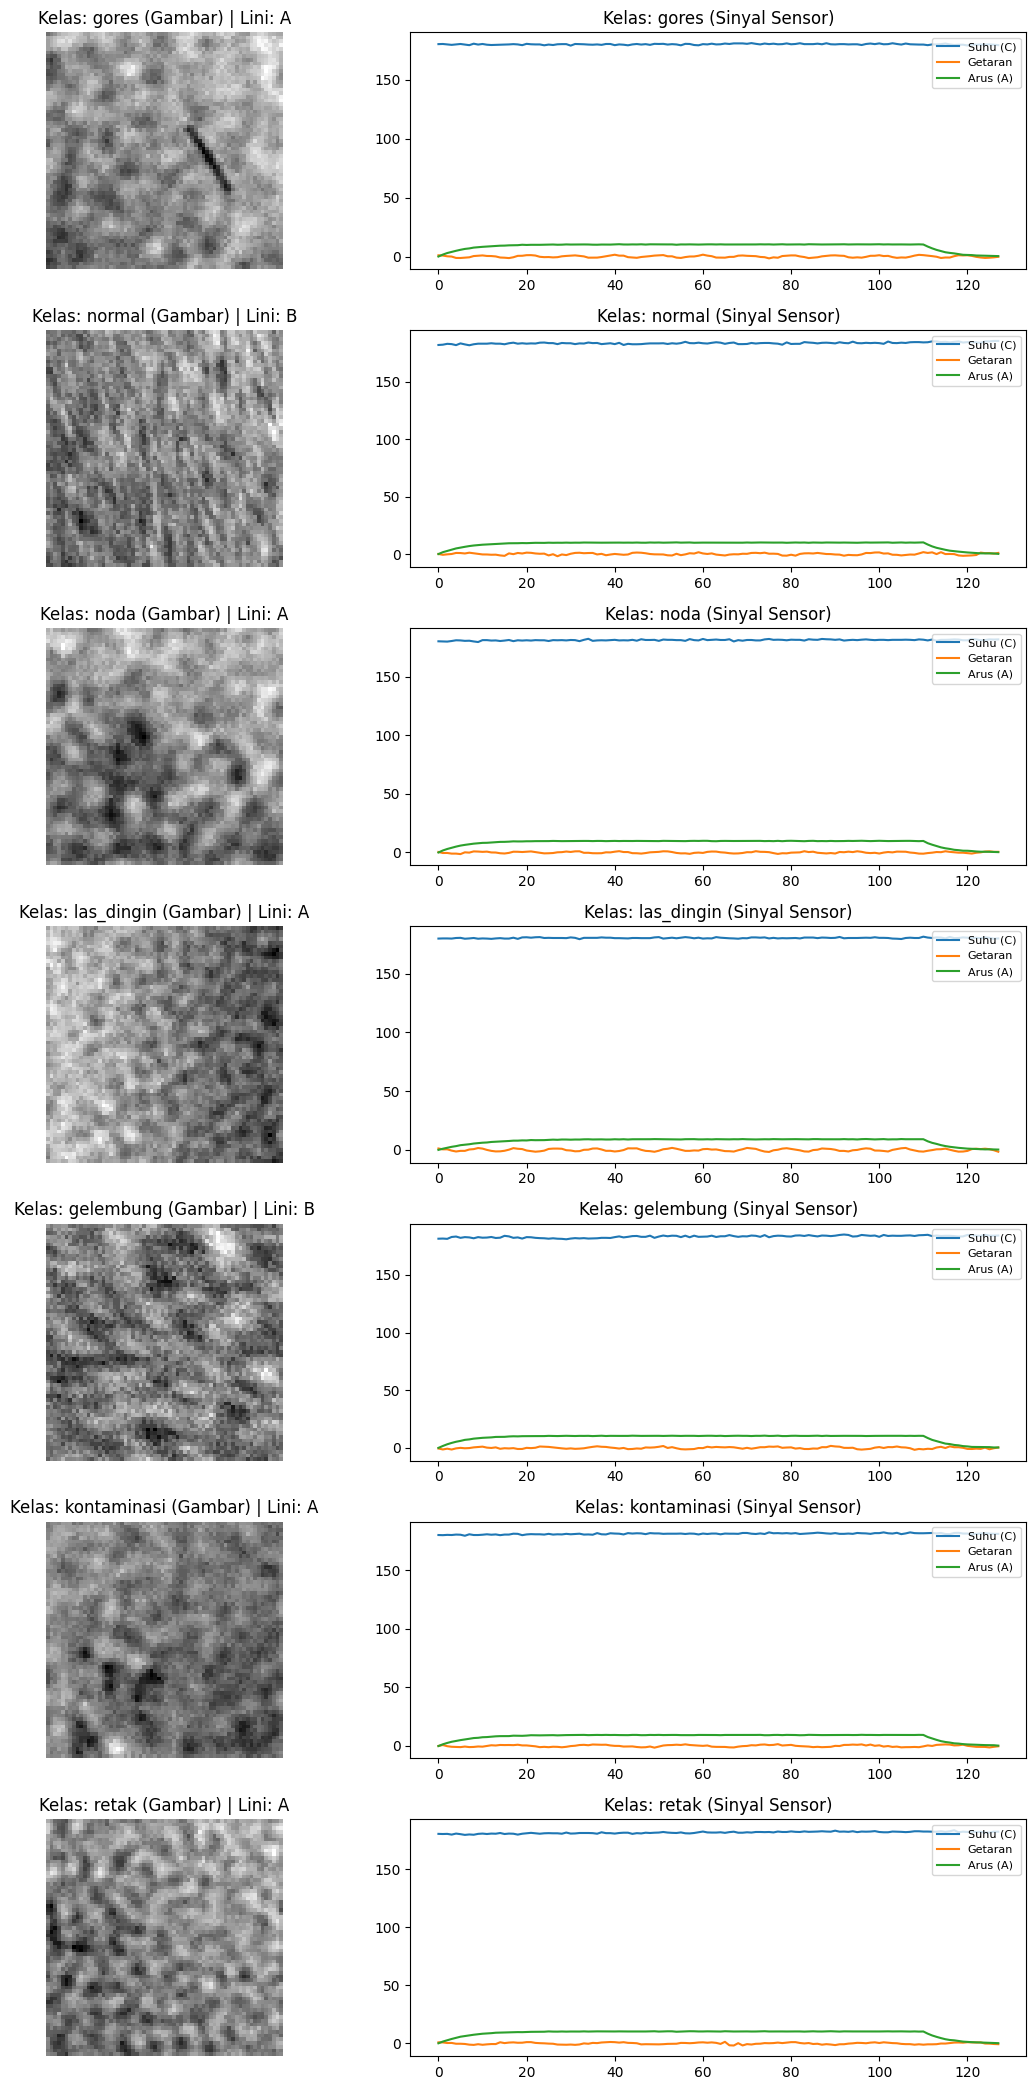

In [5]:
# 1. Cek apakah missing sensor berkaitan dengan lini produksi
meta_train['sensor_missing'] = nan_train
meta_train['sensor_partial_nan'] = partial_nan_train
print("=== PROPORSI MISSING SENSOR PER LINI (TRAIN) ===")
print(meta_train.groupby('lini')[['sensor_missing', 'sensor_partial_nan']].mean() * 100)

# Cek juga di data Test apakah ada partial NaN
partial_nan_test = np.isnan(sensor_test).any(axis=(1, 2)) & (~nan_test)
print(f"\nTest - Sensor hilang sebagian: {partial_nan_test.sum()} ({partial_nan_test.mean()*100:.2f}%)")

# 2. Visualisasi contoh 1 sampel per kelas (Gambar & Sinyal Sensor) - Poin 1a
kelas_unik = meta_train['kelas'].unique()
fig, axes = plt.subplots(len(kelas_unik), 2, figsize=(12, 3 * len(kelas_unik)))

for idx, k in enumerate(kelas_unik):
    # Cari indeks yang kelasnya k dan sensornya bersih (tidak ada NaN sama sekali)
    valid_idx = meta_train[(meta_train['kelas'] == k) & (~nan_train) & (~partial_nan_train)].index[0]

    # Plot Gambar (64x64)
    axes[idx, 0].imshow(data_train['gambar'][valid_idx], cmap='gray')
    axes[idx, 0].set_title(f"Kelas: {k} (Gambar) | Lini: {meta_train.loc[valid_idx, 'lini']}")
    axes[idx, 0].axis('off')

    # Plot Sinyal Sensor (3 channel: suhu, getaran, arus)
    sig = data_train['sensor'][valid_idx].astype(np.float32)
    axes[idx, 1].plot(sig[0], label='Suhu (C)')
    axes[idx, 1].plot(sig[1], label='Getaran')
    axes[idx, 1].plot(sig[2], label='Arus (A)')
    axes[idx, 1].set_title(f"Kelas: {k} (Sinyal Sensor)")
    axes[idx, 1].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

1b. Preprocessing, Dataset & Arsitektur Multimodal (Early Fusion vs Cross-Attention Fusion)

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report
import random
import os

# Set device (GPU T4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Menggunakan device:", device)

# Mapping 7 kelas sesuai kamus_data.md
KELAS_LIST = ['normal', 'gores', 'noda', 'retak', 'gelembung', 'las_dingin', 'kontaminasi']
label2idx = {k: i for i, k in enumerate(KELAS_LIST)}
idx2label = {i: k for i, k in enumerate(KELAS_LIST)}

# 1. Hitung statistik per-lini dari data Train untuk Per-Line Normalization (Poin 1e)
s_train_raw = data_train['sensor'].astype(np.float32)
s_test_raw = data_test['sensor'].astype(np.float32)

line_stats = {}
for l in ['A', 'B']:
    mask_l = (meta_train['lini'] == l).values
    mean_l = np.nanmean(s_train_raw[mask_l], axis=(0, 2), keepdims=True)
    std_l = np.nanstd(s_train_raw[mask_l], axis=(0, 2), keepdims=True) + 1e-6
    line_stats[l] = (mean_l[0], std_l[0]) # shape (3, 1)

def normalize_sensor_per_line(sensor_arr, lini_series):
    normed = np.zeros_like(sensor_arr, dtype=np.float32)
    valid_mask = (~np.isnan(sensor_arr)).astype(np.float32) # 1 jika valid, 0 jika NaN
    for l in ['A', 'B']:
        idx = (lini_series == l).values
        mean_l, std_l = line_stats[l]
        normed[idx] = (sensor_arr[idx] - mean_l) / std_l
    # Ganti NaN menjadi 0 setelah dinormalisasi
    normed = np.nan_to_num(normed, nan=0.0)
    return normed, valid_mask

X_img_train = data_train['gambar'].astype(np.float32) / 255.0
X_sen_train, X_mask_train = normalize_sensor_per_line(s_train_raw, meta_train['lini'])
y_train = meta_train['kelas'].map(label2idx).values

X_img_test = data_test['gambar'].astype(np.float32) / 255.0
X_sen_test, X_mask_test = normalize_sensor_per_line(s_test_raw, meta_test['lini'])

# 2. PyTorch Dataset dengan Augmentasi & Modality Dropout (Poin 1e & 1f)
class MultimodalDefectDataset(Dataset):
    def __init__(self, imgs, sens, masks, labels=None, is_train=False, mod_drop_prob=0.15):
        self.imgs = imgs
        self.sens = sens
        self.masks = masks
        self.labels = labels
        self.is_train = is_train
        self.mod_drop_prob = mod_drop_prob

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img = self.imgs[idx].copy()   # (64, 64)
        sen = self.sens[idx].copy()   # (3, 128)
        msk = self.masks[idx].copy()  # (3, 128)

        if self.is_train:
            # Augmentasi gambar ringan (flip & noise/brightness shift untuk domain shift)
            if random.random() < 0.5:
                img = np.fliplr(img).copy()
            if random.random() < 0.5:
                img = np.flipud(img).copy()
            img = np.clip(img * random.uniform(0.9, 1.1) + random.uniform(-0.05, 0.05), 0.0, 1.0)

            # Simulasi Modality Dropout (sensor mati total) agar tahan missing sensor (Poin 1f)
            if random.random() < self.mod_drop_prob:
                sen = np.zeros_like(sen)
                msk = np.zeros_like(msk)
            else:
                sen = sen + np.random.normal(0, 0.03, size=sen.shape).astype(np.float32) * msk

        # Gabungkan sinyal (3 ch) + binary mask (3 ch) -> (6, 128)
        sen_combined = np.concatenate([sen, msk], axis=0)
        img_tensor = torch.tensor(img, dtype=torch.float32).unsqueeze(0) # (1, 64, 64)
        sen_tensor = torch.tensor(sen_combined, dtype=torch.float32)      # (6, 128)

        if self.labels is not None:
            return img_tensor, sen_tensor, torch.tensor(self.labels[idx], dtype=torch.long)
        return img_tensor, sen_tensor

# 3. Encoder Gambar (2D-CNN) & Encoder Sinyal (1D-CNN + BiGRU)
class ImageEncoder(nn.Module):
    def __init__(self, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten()
        )
        self.fc = nn.Linear(128, out_dim)

    def forward(self, x):
        return F.relu(self.fc(self.net(x)))

class SignalEncoder(nn.Module):
    def __init__(self, in_ch=6, out_dim=128):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_ch, 32, kernel_size=5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1), nn.BatchNorm1d(128), nn.ReLU()
        )
        self.gru = nn.GRU(128, 64, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(128, out_dim)

    def forward(self, x):
        h = self.conv(x).transpose(1, 2) # (B, 32, 128)
        out, _ = self.gru(h)             # (B, 32, 128)
        pooled = out.mean(dim=1)         # Global average pooling temporal
        return F.relu(self.fc(pooled))

# 4. Dua Strategi Fusi untuk Perbandingan Poin 1b
class EarlyFusionNet(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.img_enc = ImageEncoder(128)
        self.sen_enc = SignalEncoder(6, 128)
        self.classifier = nn.Sequential(
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, img, sen):
        f_img = self.img_enc(img)
        f_sen = self.sen_enc(sen)
        fused = torch.cat([f_img, f_sen], dim=1)
        return self.classifier(fused)

class GatedAttentionFusionNet(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.img_enc = ImageEncoder(128)
        self.sen_enc = SignalEncoder(6, 128)
        # Gated cross-modal attention untuk menimbang bobot gambar vs sensor
        self.gate = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.Sigmoid()
        )
        self.classifier = nn.Sequential(
            nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, img, sen):
        f_img = self.img_enc(img)
        f_sen = self.sen_enc(sen)
        concat = torch.cat([f_img, f_sen], dim=1)
        weights = self.gate(concat)
        gated_feat = concat * weights
        return self.classifier(gated_feat)

print("Preprocessing Per-Line Normalization & Arsitektur Model siap!")
print(f"Shape X_img_train: {X_img_train.shape}, X_sen_train: {X_sen_train.shape}")

Menggunakan device: cuda
Preprocessing Per-Line Normalization & Arsitektur Model siap!
Shape X_img_train: (48000, 64, 64), X_sen_train: (48000, 3, 128)


1g (Sanity Check) & 1b (Perbandingan Early Fusion vs Gated Attention Fusion)

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# 1. Split Train (85%) & Validation (15%) secara stratified berdasarkan kombinasi kelas + lini
strat_key = meta_train['kelas'].astype(str) + "_" + meta_train['lini'].astype(str)
idx_all = np.arange(len(meta_train))
train_idx, val_idx = train_test_split(idx_all, test_size=0.15, random_state=42, stratify=strat_key)

# Hitung Class Weights untuk mengatasi class imbalance (meningkatkan Macro-F1)
cls_weights = compute_class_weight('balanced', classes=np.arange(7), y=y_train[train_idx])
cls_weights_tensor = torch.tensor(cls_weights, dtype=torch.float32).to(device)

train_ds = MultimodalDefectDataset(X_img_train[train_idx], X_sen_train[train_idx], X_mask_train[train_idx], y_train[train_idx], is_train=True)
val_ds   = MultimodalDefectDataset(X_img_train[val_idx], X_sen_train[val_idx], X_mask_train[val_idx], y_train[val_idx], is_train=False)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

# 2. SANITY CHECK: Overfit 1 Batch (32 sampel) - Syarat Poin 1g
print("=== 1g. SANITY CHECK (OVERFIT 1 BATCH) ===")
sanity_model = GatedAttentionFusionNet().to(device)
sanity_opt = torch.optim.Adam(sanity_model.parameters(), lr=1e-3)
b_img, b_sen, b_y = next(iter(DataLoader(val_ds, batch_size=32, shuffle=True)))
b_img, b_sen, b_y = b_img.to(device), b_sen.to(device), b_y.to(device)

for step in range(1, 101):
    sanity_model.train()
    sanity_opt.zero_grad()
    out = sanity_model(b_img, b_sen)
    loss = F.cross_entropy(out, b_y)
    loss.backward()
    sanity_opt.step()
    if step in [1, 25, 50, 100]:
        acc = (out.argmax(1) == b_y).float().mean().item() * 100
        print(f"Step {step:3d} | Loss: {loss.item():.4f} | Batch Acc: {acc:.1f}%")

# 3. Fungsi Training & Evaluasi Modular (mengukur Macro-F1 keseluruhan & per Lini A/B)
def train_and_eval(model, name, epochs=12, label_smoothing=0.05, use_class_weight=True):
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(
        weight=cls_weights_tensor if use_class_weight else None,
        label_smoothing=label_smoothing
    )

    history = {'train_loss': [], 'val_f1': []}
    best_f1 = 0.0
    best_preds = None

    for ep in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for img, sen, y in train_loader:
            img, sen, y = img.to(device), sen.to(device), y.to(device)
            optimizer.zero_grad()
            logits = model(img, sen)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
        scheduler.step()

        # Evaluasi di validation set
        model.eval()
        all_preds, all_targets = [], []
        with torch.no_grad():
            for img, sen, y in val_loader:
                img, sen = img.to(device), sen.to(device)
                preds = model(img, sen).argmax(1).cpu().numpy()
                all_preds.append(preds)
                all_targets.append(y.numpy())

        all_preds = np.concatenate(all_preds)
        all_targets = np.concatenate(all_targets)
        val_f1 = f1_score(all_targets, all_preds, average='macro')

        history['train_loss'].append(total_loss / len(train_ds))
        history['val_f1'].append(val_f1)

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_preds = all_preds.copy()
            torch.save(model.state_dict(), f"{name}_best.pt")

    # Hitung Macro-F1 per Lini (Poin 1e)
    val_lini = meta_train['lini'].values[val_idx]
    f1_A = f1_score(all_targets[val_lini == 'A'], best_preds[val_lini == 'A'], average='macro')
    f1_B = f1_score(all_targets[val_lini == 'B'], best_preds[val_lini == 'B'], average='macro')
    print(f"[{name}] Best Val Macro-F1: {best_f1:.4f} | Lini A F1: {f1_A:.4f} | Lini B F1: {f1_B:.4f}")
    return history, best_preds, all_targets

print("\n=== 1b. PERBANDINGAN STRATEGI FUSI ===")
hist_early, preds_early, y_val_true = train_and_eval(EarlyFusionNet(), "EarlyFusion", epochs=12)
hist_gated, preds_gated, _          = train_and_eval(GatedAttentionFusionNet(), "GatedAttention", epochs=12)

=== 1g. SANITY CHECK (OVERFIT 1 BATCH) ===
Step   1 | Loss: 2.0018 | Batch Acc: 12.5%
Step  25 | Loss: 0.1598 | Batch Acc: 100.0%
Step  50 | Loss: 0.0289 | Batch Acc: 100.0%
Step 100 | Loss: 0.0160 | Batch Acc: 100.0%

=== 1b. PERBANDINGAN STRATEGI FUSI ===
[EarlyFusion] Best Val Macro-F1: 0.7563 | Lini A F1: 0.8040 | Lini B F1: 0.6264
[GatedAttention] Best Val Macro-F1: 0.7681 | Lini A F1: 0.8162 | Lini B F1: 0.6322


1c. Value of Each Modality (Image-Only vs Sensor-Only vs Multimodal) & 1f. Missing Modality

In [8]:
# Gunakan num_workers=0 agar transfer data lebih cepat di Colab
train_loader_fast = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=0)
val_loader_fast   = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=0)

# Definisi Model Unimodal (1c)
class ImageOnlyNet(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.img_enc = ImageEncoder(128)
        self.classifier = nn.Sequential(
            nn.Linear(128, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def forward(self, img, sen):
        return self.classifier(self.img_enc(img))

class SensorOnlyNet(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.sen_enc = SignalEncoder(6, 128)
        self.classifier = nn.Sequential(
            nn.Linear(128, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )
    def forward(self, img, sen):
        return self.classifier(self.sen_enc(sen))

def quick_train(model, name, epochs=8):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=cls_weights_tensor, label_smoothing=0.05)
    best_f1, best_preds = 0.0, None
    for ep in range(epochs):
        model.train()
        for img, sen, y in train_loader_fast:
            img, sen, y = img.to(device), sen.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(img, sen), y)
            loss.backward()
            opt.step()
        sched.step()
        model.eval()
        preds = []
        with torch.no_grad():
            for img, sen, _ in val_loader_fast:
                preds.append(model(img.to(device), sen.to(device)).argmax(1).cpu().numpy())
        preds = np.concatenate(preds)
        f1 = f1_score(y_val_true, preds, average='macro')
        if f1 > best_f1:
            best_f1, best_preds = f1, preds
    print(f"[{name}] Val Macro-F1: {best_f1:.4f}")
    return best_preds

print("=== 1c. EVALUASI UNIMODAL VS MULTIMODAL ===")
preds_img = quick_train(ImageOnlyNet(), "ImageOnly", epochs=8)
preds_sen = quick_train(SensorOnlyNet(), "SensorOnly", epochs=8)

# Tabel Perbandingan F1 per Kelas (untuk laporan Poin 1c)
df_f1_kelas = pd.DataFrame({
    'Kelas': KELAS_LIST,
    'ImageOnly_F1': f1_score(y_val_true, preds_img, average=None),
    'SensorOnly_F1': f1_score(y_val_true, preds_sen, average=None),
    'Multimodal_Gated_F1': f1_score(y_val_true, preds_gated, average=None)
}).round(4)
print("\n=== PERBANDINGAN F1-SCORE PER KELAS (POIN 1c) ===")
print(df_f1_kelas.to_string(index=False))

# === 1f. UJI KETAHANAN SAAT SENSOR HILANG (MISSING MODALITY) ===
best_gated = GatedAttentionFusionNet().to(device)
best_gated.load_state_dict(torch.load("GatedAttention_best.pt"))
best_gated.eval()

# Uji pada subset validasi yang sensornya asli NaN vs sensor di-nol-kan paksa
val_nan_mask = nan_train[val_idx]
preds_sensor_dropped = []
with torch.no_grad():
    for img, sen, _ in val_loader_fast:
        img = img.to(device)
        zero_sen = torch.zeros_like(sen).to(device) # Simulasi sensor mati total (0 + mask=0)
        preds_sensor_dropped.append(best_gated(img, zero_sen).argmax(1).cpu().numpy())
preds_sensor_dropped = np.concatenate(preds_sensor_dropped)

print("\n=== 1f. UJI MISSING MODALITY (GATED ATTENTION) ===")
print(f"F1 Normal (Sensor Tersedia + 5% NaN Asli): {f1_score(y_val_true, preds_gated, average='macro'):.4f}")
print(f"F1 Hanya pada Sampel Validasi yang Sensornya Asli NaN (n={val_nan_mask.sum()}): {f1_score(y_val_true[val_nan_mask], preds_gated[val_nan_mask], average='macro'):.4f}")
print(f"F1 Jika Sensor Dimatikan Total (100% Dropped): {f1_score(y_val_true, preds_sensor_dropped, average='macro'):.4f}")

=== 1c. EVALUASI UNIMODAL VS MULTIMODAL ===
[ImageOnly] Val Macro-F1: 0.4283
[SensorOnly] Val Macro-F1: 0.4045

=== PERBANDINGAN F1-SCORE PER KELAS (POIN 1c) ===
      Kelas  ImageOnly_F1  SensorOnly_F1  Multimodal_Gated_F1
     normal        0.1839         0.5775               0.8342
      gores        0.4852         0.0271               0.6055
       noda        0.8094         0.1594               0.8127
      retak        0.3023         0.4579               0.6572
  gelembung        0.2590         0.6610               0.7280
 las_dingin        0.2082         0.9329               0.9339
kontaminasi        0.7497         0.0157               0.8055

=== 1f. UJI MISSING MODALITY (GATED ATTENTION) ===
F1 Normal (Sensor Tersedia + 5% NaN Asli): 0.7681
F1 Hanya pada Sampel Validasi yang Sensornya Asli NaN (n=368): 0.4852
F1 Jika Sensor Dimatikan Total (100% Dropped): 0.4923


1d. Imperfect Labels (Deteksi Label Noise & Label Smoothing) & 1e. Eksperimen Domain Shift

In [9]:
# === 1d. DETEKSI INDIKASI LABEL NOISE DARI INSPEKTUR ===
best_gated.eval()
val_probs, val_losses = [], []
with torch.no_grad():
    for img, sen, y in val_loader_fast:
        img, sen, y = img.to(device), sen.to(device), y.to(device)
        logits = best_gated(img, sen)
        probs = F.softmax(logits, dim=1)
        losses = F.cross_entropy(logits, y, reduction='none')
        val_probs.append(probs.cpu().numpy())
        val_losses.append(losses.cpu().numpy())

val_probs = np.concatenate(val_probs)
val_losses = np.concatenate(val_losses)
pred_conf = val_probs.max(axis=1)
pred_cls = val_probs.argmax(axis=1)

# Cari sampel di mana model sangat yakin (>90%) tapi berbeda dengan label inspektur
suspect_noise = (pred_conf > 0.90) & (pred_cls != y_val_true)
print(f"=== 1d. DETEKSI LABEL NOISE ===")
print(f"Sampel validasi terindikasi salah label (conf > 90% tapi beda label): {suspect_noise.sum()} dari {len(y_val_true)} ({suspect_noise.mean()*100:.2f}%)")

# Tampilkan 5 contoh teratas kandidat label noise
top_noise_idx = np.argsort(-val_losses)[:5]
df_noise = pd.DataFrame({
    'id_unit': meta_train['id_unit'].values[val_idx[top_noise_idx]],
    'lini': meta_train['lini'].values[val_idx[top_noise_idx]],
    'label_inspektur': [idx2label[i] for i in y_val_true[top_noise_idx]],
    'prediksi_model': [idx2label[i] for i in pred_cls[top_noise_idx]],
    'confidence': np.round(pred_conf[top_noise_idx], 4)
})
print("\nContoh 5 Kandidat Salah Label (Inspektur vs Model):")
print(df_noise.to_string(index=False))

# Eksperimen Ablasi 1d & 1e: Tanpa Label Smoothing vs Dengan Label Smoothing, serta Domain Shift
def train_ablation(label_smooth=0.0, boost_line_b=False, epochs=8):
    model = GatedAttentionFusionNet().to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(weight=cls_weights_tensor, label_smoothing=label_smooth)

    # Jika boost_line_b=True, gandakan sampel Lini B saat training untuk atasi domain shift (60% test adalah Lini B)
    if boost_line_b:
        lini_tr = meta_train['lini'].values[train_idx]
        idx_b = np.where(lini_tr == 'B')[0]
        aug_indices = np.concatenate([np.arange(len(train_idx)), idx_b])
        ds_use = torch.utils.data.Subset(train_ds, aug_indices)
        loader_use = DataLoader(ds_use, batch_size=128, shuffle=True, num_workers=0)
    else:
        loader_use = train_loader_fast

    best_f1, best_p = 0.0, None
    for ep in range(epochs):
        model.train()
        for img, sen, y in loader_use:
            img, sen, y = img.to(device), sen.to(device), y.to(device)
            opt.zero_grad()
            loss = crit(model(img, sen), y)
            loss.backward()
            opt.step()
        sched.step()
        model.eval()
        preds = []
        with torch.no_grad():
            for img, sen, _ in val_loader_fast:
                preds.append(model(img.to(device), sen.to(device)).argmax(1).cpu().numpy())
        preds = np.concatenate(preds)
        f1 = f1_score(y_val_true, preds, average='macro')
        if f1 > best_f1:
            best_f1, best_p = f1, preds

    val_lini = meta_train['lini'].values[val_idx]
    f1_A = f1_score(y_val_true[val_lini == 'A'], best_p[val_lini == 'A'], average='macro')
    f1_B = f1_score(y_val_true[val_lini == 'B'], best_p[val_lini == 'B'], average='macro')
    return best_f1, f1_A, f1_B

print("\n=== PERBANDINGAN ABLASI 1d (LABEL SMOOTHING) & 1e (OVERSAMPLING LINI B) ===")
f1_no_ls, a_no_ls, b_no_ls = train_ablation(label_smooth=0.0, boost_line_b=False, epochs=8)
print(f"1. Tanpa Label Smoothing (LS=0.0)          -> Macro-F1: {f1_no_ls:.4f} | Lini A: {a_no_ls:.4f} | Lini B: {b_no_ls:.4f}")

f1_ls_b, a_ls_b, b_ls_b = train_ablation(label_smooth=0.1, boost_line_b=True, epochs=8)
print(f"2. Label Smoothing (0.1) + Boost Lini B    -> Macro-F1: {f1_ls_b:.4f} | Lini A: {a_ls_b:.4f} | Lini B: {b_ls_b:.4f}")

=== 1d. DETEKSI LABEL NOISE ===
Sampel validasi terindikasi salah label (conf > 90% tapi beda label): 93 dari 7200 (1.29%)

Contoh 5 Kandidat Salah Label (Inspektur vs Model):
id_unit lini label_inspektur prediksi_model  confidence
U313158    B          normal     las_dingin      0.9608
U852396    B          normal     las_dingin      0.9582
U896270    B          normal     las_dingin      0.9525
U605921    B          normal     las_dingin      0.9374
U467278    B       gelembung          retak      0.8870

=== PERBANDINGAN ABLASI 1d (LABEL SMOOTHING) & 1e (OVERSAMPLING LINI B) ===
1. Tanpa Label Smoothing (LS=0.0)          -> Macro-F1: 0.7257 | Lini A: 0.7574 | Lini B: 0.6382
2. Label Smoothing (0.1) + Boost Lini B    -> Macro-F1: 0.7439 | Lini A: 0.7853 | Lini B: 0.6283


1g. Multi-Seed Evaluation (3 Seeds), Learning Curves & Export prediksi_klasifikasi.csv


--- Melatih Model Final dengan Seed = 42 ---
Seed 42 Selesai -> Best Macro-F1: 0.7632 | Lini A: 0.8125 | Lini B: 0.6308

--- Melatih Model Final dengan Seed = 100 ---
Seed 100 Selesai -> Best Macro-F1: 0.7630 | Lini A: 0.8177 | Lini B: 0.6169

--- Melatih Model Final dengan Seed = 2026 ---
Seed 2026 Selesai -> Best Macro-F1: 0.7736 | Lini A: 0.8200 | Lini B: 0.6411

HASIL AKHIR 3 SEED (GatedAttentionFusionNet):
Val Macro-F1 Keseluruhan : 0.7666 ± 0.0049
Val Macro-F1 Lini A      : 0.8167 ± 0.0032
Val Macro-F1 Lini B      : 0.6296 ± 0.0099


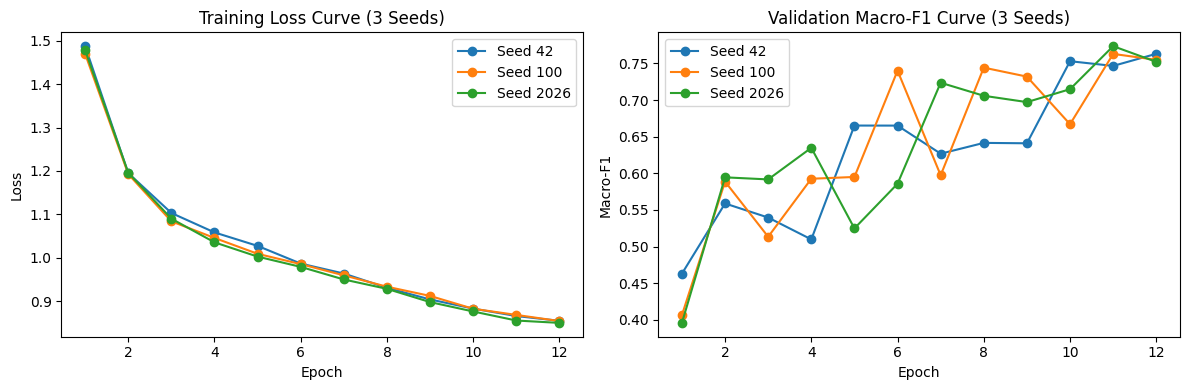


File berhasil disimpan ke: /content/drive/MyDrive/data_uts_dl/prediksi_klasifikasi.csv
Total baris prediksi: 16000 | Cek NaN: 0

Distribusi Prediksi Kelas pada Data Test (16.000 sampel):
kelas
normal         6402
gores          2401
noda           1698
gelembung      1693
retak          1536
las_dingin     1434
kontaminasi     836
Name: count, dtype: int64

5 Baris Pertama prediksi_klasifikasi.csv:
   id_unit      kelas
0  U412019      gores
1  U929275      gores
2  U845264  gelembung
3  U382231     normal
4  U156089      gores


In [10]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

# Siapkan DataLoader untuk Test Set (16.000 sampel)
test_ds = MultimodalDefectDataset(X_img_test, X_sen_test, X_mask_test, labels=None, is_train=False)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=0)

SEEDS = [42, 100, 2026]
EPOCHS_FINAL = 12

seed_f1_scores = []
seed_f1_A = []
seed_f1_B = []
all_histories = []
test_probs_ensemble = np.zeros((len(meta_test), 7), dtype=np.float32)

val_lini = meta_train['lini'].values[val_idx]

for s in SEEDS:
    print(f"\n--- Melatih Model Final dengan Seed = {s} ---")
    set_seed(s)
    model = GatedAttentionFusionNet().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_FINAL)
    criterion = nn.CrossEntropyLoss(weight=cls_weights_tensor, label_smoothing=0.05)

    hist = {'train_loss': [], 'val_f1': []}
    best_f1 = 0.0
    best_preds = None

    for ep in range(1, EPOCHS_FINAL + 1):
        model.train()
        total_loss = 0.0
        for img, sen, y in train_loader_fast:
            img, sen, y = img.to(device), sen.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(img, sen), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)
        scheduler.step()

        # Evaluasi validasi
        model.eval()
        v_preds = []
        with torch.no_grad():
            for img, sen, _ in val_loader_fast:
                v_preds.append(model(img.to(device), sen.to(device)).argmax(1).cpu().numpy())
        v_preds = np.concatenate(v_preds)
        v_f1 = f1_score(y_val_true, v_preds, average='macro')

        hist['train_loss'].append(total_loss / len(train_ds))
        hist['val_f1'].append(v_f1)

        if v_f1 > best_f1:
            best_f1 = v_f1
            best_preds = v_preds.copy()
            torch.save(model.state_dict(), f"final_gated_seed_{s}.pt")

    f1_a = f1_score(y_val_true[val_lini == 'A'], best_preds[val_lini == 'A'], average='macro')
    f1_b = f1_score(y_val_true[val_lini == 'B'], best_preds[val_lini == 'B'], average='macro')
    seed_f1_scores.append(best_f1)
    seed_f1_A.append(f1_a)
    seed_f1_B.append(f1_b)
    all_histories.append(hist)
    print(f"Seed {s} Selesai -> Best Macro-F1: {best_f1:.4f} | Lini A: {f1_a:.4f} | Lini B: {f1_b:.4f}")

    # Prediksi probabilitas data Test menggunakan bobot terbaik seed ini
    model.load_state_dict(torch.load(f"final_gated_seed_{s}.pt"))
    model.eval()
    t_probs = []
    with torch.no_grad():
        for img, sen in test_loader:
            logits = model(img.to(device), sen.to(device))
            t_probs.append(F.softmax(logits, dim=1).cpu().numpy())
    test_probs_ensemble += np.concatenate(t_probs) / len(SEEDS)

print("\n=======================================================")
print(f"HASIL AKHIR 3 SEED (GatedAttentionFusionNet):")
print(f"Val Macro-F1 Keseluruhan : {np.mean(seed_f1_scores):.4f} ± {np.std(seed_f1_scores):.4f}")
print(f"Val Macro-F1 Lini A      : {np.mean(seed_f1_A):.4f} ± {np.std(seed_f1_A):.4f}")
print(f"Val Macro-F1 Lini B      : {np.mean(seed_f1_B):.4f} ± {np.std(seed_f1_B):.4f}")
print("=======================================================")

# Plot Learning Curves (untuk laporan.pdf Poin 1g)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for idx, s in enumerate(SEEDS):
    ax[0].plot(range(1, EPOCHS_FINAL + 1), all_histories[idx]['train_loss'], marker='o', label=f'Seed {s}')
    ax[1].plot(range(1, EPOCHS_FINAL + 1), all_histories[idx]['val_f1'], marker='o', label=f'Seed {s}')
ax[0].set_title("Training Loss Curve (3 Seeds)")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()
ax[1].set_title("Validation Macro-F1 Curve (3 Seeds)")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Macro-F1")
ax[1].legend()
plt.tight_layout()
plt.show()

# Buat file prediksi_klasifikasi.csv dan simpan ke Google Drive
final_test_preds = test_probs_ensemble.argmax(axis=1)
df_sub = pd.DataFrame({
    'id_unit': meta_test['id_unit'],
    'kelas': [idx2label[i] for i in final_test_preds]
})

output_csv_path = path + 'prediksi_klasifikasi.csv'
df_sub.to_csv(output_csv_path, index=False)
print(f"\nFile berhasil disimpan ke: {output_csv_path}")
print(f"Total baris prediksi: {len(df_sub)} | Cek NaN: {df_sub.isna().sum().sum()}")
print("\nDistribusi Prediksi Kelas pada Data Test (16.000 sampel):")
print(df_sub['kelas'].value_counts())
print("\n5 Baris Pertama prediksi_klasifikasi.csv:")
print(df_sub.head())